Model solved successfully.

Instance: NEWCASTLE-09-BASE
Objective value: $642,942,697.72

OBJECTIVE BREAKDOWN
-------------------
Design / operating cost: $605,151,181.49
Emission cost:           $6,986,616.23
Unmet-demand penalty:    $30,804,900.00
Total objective:         $642,942,697.72

OPTIMAL NETWORK DESIGN

Dry port: Tamworth
----------------------------------------
Demand: 50695.2 TEU
Dry port opened: YES
Direct delivery selected: NO
Modes:
   road     selected = YES   flow = 11095.20 TEU
   rail     selected = YES   flow = 39600.00 TEU

Flow through dry port: 50695.20 TEU
Direct-delivery flow:      0.00 TEU
Unmet demand:              0.00 TEU
Total allocation:      50695.20 TEU

Dry port: Narrabri
----------------------------------------
Demand: 76085.4 TEU
Dry port opened: YES
Direct delivery selected: NO
Modes:
   road     selected = YES   flow = 34887.00 TEU
   rail     selected = YES   flow = 39200.00 TEU

Flow through dry port: 74087.00 TEU
Direct-delivery flow:      0.00

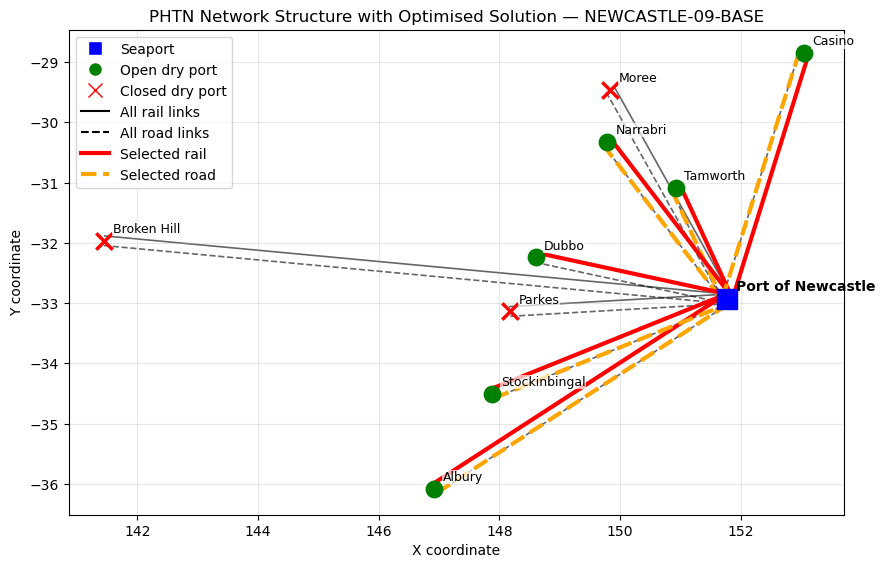

In [1]:
#=====================================================
# Stage 1: Normal PHTN Network Design Model
#=====================================================

from sage.all import *
import csv
import json
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import math
import random
from sage.all import MixedIntegerLinearProgram



# 1. Load Data

DATA_FOLDER = DATA_FOLDER = Path(".")

DRY_PORT_FILE = DATA_FOLDER / "newcastle_dry_port.csv"
MODE_FILE = DATA_FOLDER / "newcastle_mode_parameter.csv"
METADATA_FILE = DATA_FOLDER / "newcastle_metadata.json"

# 2. READ INPUT FILES

def load_inputs(dry_port_file, mode_file, metadata_file):
    dry_df = pd.read_csv(dry_port_file)
    mode_df = pd.read_csv(mode_file)

    with open(metadata_file, "r", encoding="utf-8") as f:
        metadata = json.load(f)
        
    dry_df.columns = dry_df.columns.str.strip()
    mode_df.columns = mode_df.columns.str.strip()

    dry_df["dry_port_id"] = dry_df["dry_port_id"].str.strip()
    mode_df["dry_port_id"] = mode_df["dry_port_id"].str.strip()
    mode_df["mode"] = mode_df["mode"].str.strip()
    
    dry_ports = (
        dry_df
        .set_index("dry_port_id")
        .to_dict(orient="index")
    )

    mode_parameters = (
        mode_df
        .set_index(["dry_port_id", "mode"])
        .to_dict(orient="index")
    )

    return dry_ports, mode_parameters, metadata

dry_ports, mode_parameters, metadata = load_inputs(
    DRY_PORT_FILE,
    MODE_FILE,
    METADATA_FILE
)
        
    
    
for d in dry_ports:
    dry_ports[d]["opening_cost"] *= 0.75
    dry_ports[d]["direct_delivery_emissions"]*=0.675155/0.673155

    
metadata["unmet_penalty"]=1500
    
    
    
    
    
    

# 3. BUILD THE PHTN MODEL
def build_model(dry_ports, mode_parameters, metadata):

    # Sets

    D = list(dry_ports.keys())
    M = list(metadata["modes"])

    # Model parameters
    # D_d
    Demand = {
        d: dry_ports[d]["demand"]
        for d in D
    }

    # K_d
    K = {
        d: dry_ports[d]["dry_port_capacity"]
        for d in D
    }

    # Q_dm
    Q = {
        (d, m): mode_parameters[d, m]["connection_capacity"]
        for d in D
        for m in M
    }

    # C^opening_d
    C_opening = {
        d: dry_ports[d]["opening_cost"]
        for d in D
    }

    # C^transport_dm
    C_transport = {
        (d, m): mode_parameters[d, m]["transport_cost"]
        for d in D
        for m in M
    }

    # C^processing_d
    C_processing = {
        d: dry_ports[d]["processing_cost"]
        for d in D
    }

    # C^direct_d
    C_direct = {
        d: dry_ports[d]["direct_delivery_cost"]
        for d in D
    }

    # E^transport_dm
    E_transport = {
        (d, m): mode_parameters[d, m]["transport_emissions"]
        for d in D
        for m in M
    }

    # E^processing_d
    E_processing = {
        d: dry_ports[d]["processing_emissions"]
        for d in D
    }

    # E^direct_d
    E_direct = {
        d: dry_ports[d]["direct_delivery_emissions"]
        for d in D
    }

    # E^cost
    E_cost = metadata["emission_cost_per_kg"]

    # C^unmet
    C_unmet = metadata["unmet_penalty"]

    
    # Create minimisation MILP
    model = MixedIntegerLinearProgram(
        maximization=False
    )

    # DECISION VARIABLES
    # Equation (12) y_d = 1 if dry port d is opened
    y = model.new_variable(binary=True)


    # Equation (13) z^dir_d = 1 if direct delivery is selected
    z_dir = model.new_variable(binary=True)


    # Equation (14) z_dm = 1 if mode m is activated at dry port d
    z = model.new_variable(binary=True)


    # Equation (15) x_dm >= 0 Flow through dry port d using mode m
    x = model.new_variable(nonnegative=True)


    # Equation (16) w_d >= 0 Direct-delivery flow
    w = model.new_variable(nonnegative=True)


    # Equation (17) U_d >= 0 Unmet demand
    U = model.new_variable(nonnegative=True)

    # COST EXPRESSIONS
    
    # Equation (2) C_design
    C_design = (
        sum(C_opening[d] * y[d]
            for d in D)
        +sum(C_transport[d, m] * x[d, m]
            for d in D
            for m in M)
        +sum(C_processing[d] *sum(x[d, m] for m in M)
            for d in D)
        +sum(C_direct[d] * w[d]
            for d in D)
    )

    # Equation (3) C_emission
    C_emission = E_cost * (
        sum(E_transport[d, m] * x[d, m]
            for d in D
            for m in M)
        +sum(E_processing[d] * sum(x[d, m] for m in M)
            for d in D)
        +sum(E_direct[d] * w[d]
            for d in D)
    )

    # Equation (4) C_penalty
    C_penalty = sum(C_unmet * U[d]
        for d in D)
    
    # Objective Function
    # Equation (1)
    C_total = (C_design + C_emission + C_penalty)

    model.set_objective(C_total)


    # ========================================================
    # CONSTRAINTS
    # ========================================================

    for d in D:


        # ----------------------------------------------------
        # Equation (5)
        #
        # Demand balance
        #
        # sum_m x_dm + w_d + U_d = D_d
        # ----------------------------------------------------

        model.add_constraint(

            sum(
                x[d, m]
                for m in M
            )

            + w[d]
            + U[d]

            == Demand[d]
        )


        # ----------------------------------------------------
        # Equation (6)
        #
        # Dry-port capacity
        #
        # sum_m x_dm <= K_d y_d
        # ----------------------------------------------------

        model.add_constraint(

            sum(
                x[d, m]
                for m in M
            )

            <= K[d] * y[d]
        )


        # ----------------------------------------------------
        # Equation (7)
        #
        # Direct-delivery activation
        #
        # w_d <= D_d z^dir_d
        # ----------------------------------------------------

        model.add_constraint(

            w[d]
            <= Demand[d] * z_dir[d]
        )


        # ----------------------------------------------------
        # Equation (10)
        #
        # If dry port is opened, at least one mode
        # must be activated
        #
        # y_d <= sum_m z_dm
        # ----------------------------------------------------

        model.add_constraint(

            y[d]
            <= sum(
                z[d, m]
                for m in M
            )
        )


        for m in M:


            # ------------------------------------------------
            # Equation (8)
            #
            # Connection capacity
            #
            # x_dm <= Q_dm z_dm
            # ------------------------------------------------

            model.add_constraint(

                x[d, m]
                <= Q[d, m] * z[d, m]
            )


            # ------------------------------------------------
            # Equation (9)
            #
            # Cannot activate a mode unless
            # the dry port is opened
            #
            # z_dm <= y_d
            # ------------------------------------------------

            model.add_constraint(

                z[d, m]
                <= y[d]
            )


            # ------------------------------------------------
            # Equation (11)
            #
            # Direct delivery and dry-port transport
            # cannot both be selected
            #
            # z^dir_d + z_dm <= 1
            # ------------------------------------------------

            model.add_constraint(

                z_dir[d] + z[d, m]
                <= 1
            )


    # Everything required later
    data = {

        "D": D,
        "M": M,

        "Demand": Demand,
        "K": K,
        "Q": Q,

        "C_opening": C_opening,
        "C_transport": C_transport,
        "C_processing": C_processing,
        "C_direct": C_direct,

        "E_transport": E_transport,
        "E_processing": E_processing,
        "E_direct": E_direct,

        "E_cost": E_cost,
        "C_unmet": C_unmet
    }


    variables = {
        "y": y,
        "z_dir": z_dir,
        "z": z,
        "x": x,
        "w": w,
        "U": U
    }


    expressions = {
        "C_design": C_design,
        "C_emission": C_emission,
        "C_penalty": C_penalty,
        "C_total": C_total
    }


    return model, variables, expressions, data

model, variables, expressions, data = build_model(
    dry_ports,
    mode_parameters,
    metadata
)

#============================================================
# 5. SOLVE
# ============================================================

objective_value = model.solve()

print("Model solved successfully.")
print()
print("Instance:", metadata["instance_id"])
print("Objective value: ${:,.2f}".format(objective_value))


# ============================================================
# 6. EXTRACT DECISION VARIABLES
# ============================================================

y_value = model.get_values(variables["y"])
z_dir_value = model.get_values(variables["z_dir"])
z_value = model.get_values(variables["z"])

x_value = model.get_values(variables["x"])
w_value = model.get_values(variables["w"])
U_value = model.get_values(variables["U"])


# ============================================================
# 7. CALCULATE OBJECTIVE COMPONENTS
# ============================================================

D = data["D"]
M = data["M"]


design_cost_value = (

    sum(
        data["C_opening"][d] * y_value[d]
        for d in D
    )

    +

    sum(
        data["C_transport"][d, m] * x_value[d, m]
        for d in D
        for m in M
    )

    +

    sum(
        data["C_processing"][d] *
        sum(x_value[d, m] for m in M)
        for d in D
    )

    +

    sum(
        data["C_direct"][d] * w_value[d]
        for d in D
    )
)


emission_cost_value = data["E_cost"] * (

    sum(
        data["E_transport"][d, m] * x_value[d, m]
        for d in D
        for m in M
    )

    +

    sum(
        data["E_processing"][d] *
        sum(x_value[d, m] for m in M)
        for d in D
    )

    +

    sum(
        data["E_direct"][d] * w_value[d]
        for d in D
    )
)


penalty_cost_value = sum(
    data["C_unmet"] * U_value[d]
    for d in D
)


print()
print("OBJECTIVE BREAKDOWN")
print("-------------------")

print(
    "Design / operating cost: ${:,.2f}"
    .format(design_cost_value)
)

print(
    "Emission cost:           ${:,.2f}"
    .format(emission_cost_value)
)

print(
    "Unmet-demand penalty:    ${:,.2f}"
    .format(penalty_cost_value)
)

print(
    "Total objective:         ${:,.2f}"
    .format(
        design_cost_value
        + emission_cost_value
        + penalty_cost_value
    )
)




# ============================================================
# 8. REPORT NETWORK DESIGN AND FLOW ALLOCATION
# ============================================================

TOL = 1e-6


print()
print("=" * 70)
print("OPTIMAL NETWORK DESIGN")
print("=" * 70)


for d in D:

    demand = data["Demand"][d]

    opened = y_value[d] > 0.5
    direct_selected = z_dir_value[d] > 0.5

    dry_port_flow = sum(
        x_value[d, m]
        for m in M
    )

    direct_flow = w_value[d]
    unmet = U_value[d]


    print()
    print("Dry port:", d)
    print("-" * 40)

    print("Demand:", demand, "TEU")

    print(
        "Dry port opened:",
        "YES" if opened else "NO"
    )

    print(
        "Direct delivery selected:",
        "YES" if direct_selected else "NO"
    )


    print("Modes:")

    for m in M:

        active = z_value[d, m] > 0.5
        flow = x_value[d, m]

        print(
            "   {:<8} selected = {:<3}   flow = {:8.2f} TEU"
            .format(
                m,
                "YES" if active else "NO",
                flow
            )
        )


    print()
    print(
        "Flow through dry port: {:8.2f} TEU"
        .format(dry_port_flow)
    )

    print(
        "Direct-delivery flow:  {:8.2f} TEU"
        .format(direct_flow)
    )

    print(
        "Unmet demand:          {:8.2f} TEU"
        .format(unmet)
    )

    print(
        "Total allocation:      {:8.2f} TEU"
        .format(
            dry_port_flow
            + direct_flow
            + unmet
        )
    )
    

    
# 8. Visualisation
def plot_network_with_solution(
    dry_ports,
    mode_parameters,
    metadata,
    data,
    y_value,
    z_value
):
    fig, ax = plt.subplots(figsize=(10, 8))

    # Controls the separation between road and rail
    LINK_OFFSET = 0.08  # Previously 0.6

    # -----------------------------
    # Seaport
    # -----------------------------
    sx = metadata["seaport"]["x_coordinate"]
    sy = metadata["seaport"]["y_coordinate"]
    seaport_id = metadata["seaport"]["seaport_id"]

    ax.scatter(sx, sy, marker="s", s=220, color="blue", zorder=4)
    ax.annotate(
        seaport_id,
        (sx, sy),
        xytext=(6, 6),
        textcoords="offset points",
        fontweight="bold",
        zorder=5
    )

    # -----------------------------
    # Dry ports + links
    # -----------------------------
    for d, port in dry_ports.items():
        px = port["x_coordinate"]
        py = port["y_coordinate"]

        # Direction vector from dry port to seaport
        dx = sx - px
        dy = sy - py
        length = np.sqrt(dx**2 + dy**2)

        if length == 0:
            offset_x, offset_y = 0, 0
        else:
            offset_x = -dy / length
            offset_y = dx / length

        # -----------------------------
        # Draw all possible links
        # -----------------------------
        for m in metadata["modes"]:
            if (d, m) not in mode_parameters:
                continue

            if m == "rail":
                offset = LINK_OFFSET
                linestyle = "-"
            elif m == "road":
                offset = -LINK_OFFSET
                linestyle = "--"
            else:
                offset = 0
                linestyle = ":"

            x1 = px + offset * offset_x
            y1 = py + offset * offset_y
            x2 = sx + offset * offset_x
            y2 = sy + offset * offset_y

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="black",
                linestyle=linestyle,
                linewidth=1.2,
                alpha=0.6,
                zorder=1
            )

        # -----------------------------
        # Overlay selected links
        # -----------------------------
        for m in metadata["modes"]:
            if (d, m) not in mode_parameters:
                continue

            if z_value[d, m] <= 0.5:
                continue

            if m == "rail":
                offset = LINK_OFFSET
                linestyle = "-"
                highlight_color = "red"
            elif m == "road":
                offset = -LINK_OFFSET
                linestyle = "--"
                highlight_color = "orange"
            else:
                offset = 0
                linestyle = ":"
                highlight_color = "purple"

            x1 = px + offset * offset_x
            y1 = py + offset * offset_y
            x2 = sx + offset * offset_x
            y2 = sy + offset * offset_y

            ax.plot(
                [x1, x2],
                [y1, y2],
                color=highlight_color,
                linestyle=linestyle,
                linewidth=3.0,
                zorder=3
            )

        # -----------------------------
        # Plot dry port status
        # -----------------------------
        opened = y_value[d] > 0.5

        if opened:
            ax.scatter(
                px, py,
                marker="o",
                s=140,
                color="green",
                zorder=4
            )
        else:
            ax.scatter(
                px, py,
                marker="x",
                s=140,
                color="red",
                linewidths=2.5,
                zorder=4
            )

        # Name only; markers indicate open/closed status
        ax.annotate(
            d,
            (px, py),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
            zorder=5,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.7,
                pad=0.5
            )
        )

    # -----------------------------
    # Legend
    # -----------------------------
    from matplotlib.lines import Line2D

    legend_items = [
        Line2D([0], [0], marker="s", color="w",
               markerfacecolor="blue", markersize=10,
               label="Seaport"),
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor="green", markersize=10,
               label="Open dry port"),
        Line2D([0], [0], marker="x", color="red",
               markersize=10, linewidth=0,
               label="Closed dry port"),
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, label="All rail links"),
        Line2D([0], [0], color="black", linestyle="--",
               linewidth=1.5, label="All road links"),
        Line2D([0], [0], color="red", linestyle="-",
               linewidth=3, label="Selected rail"),
        Line2D([0], [0], color="orange", linestyle="--",
               linewidth=3, label="Selected road")
    ]

    ax.legend(handles=legend_items, loc="best")

    ax.set_title(
        f"PHTN Network Structure with Optimised Solution — {metadata['instance_id']}"
    )
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    plt.show()


plot_network_with_solution(
    dry_ports,
    mode_parameters,
    metadata,
    data,
    y_value,
    z_value
)


Generated 6000 scenarios, with 2 event(s) per scenario.


Completed 1000 / 6000 scenarios


Completed 2000 / 6000 scenarios


Completed 3000 / 6000 scenarios


Completed 4000 / 6000 scenarios


Completed 5000 / 6000 scenarios


Completed 6000 / 6000 scenarios


/tmp/ipykernel_33/519558924.py:1270: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([events_df.loc[events_df.hazard == h, "resilience"].values


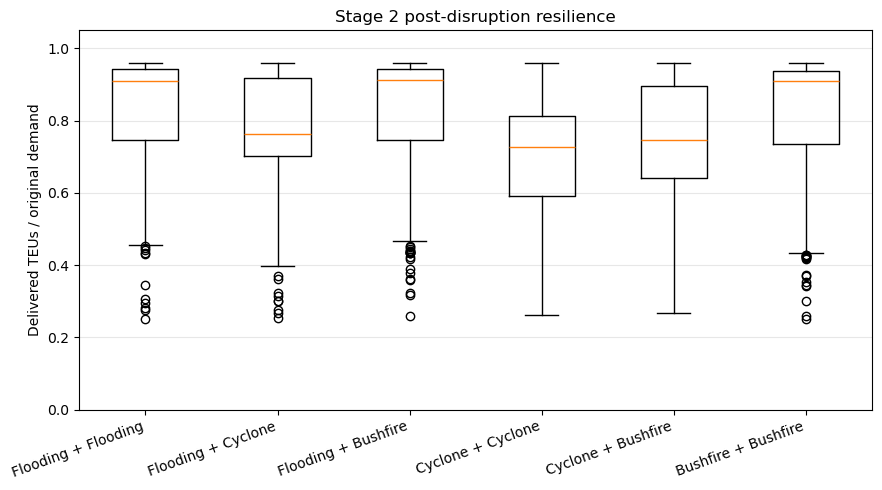


MODSIM-style results (conditional recovery selection frequencies):
           Scenario  Mean Resilience  SD Resilience Mean CO2 (kg/TEU)  S1 (%)  S2 (%)  H1 (%)  H2 (%)  H3 (%)  H4 (%)
Flooding + Flooding             0.84           0.14        280.005701   84.75   15.25    5.65    6.15    4.77   83.43
 Flooding + Cyclone             0.77           0.15        280.929627   78.85   21.15    4.98    3.09    3.12   88.81
Flooding + Bushfire             0.83           0.14        280.657107   85.71   14.29    3.75    3.20    2.92   90.12
  Cyclone + Cyclone             0.70           0.15        281.810644   80.12   19.88    3.27    1.02    2.83   92.89
 Cyclone + Bushfire             0.75           0.16        281.438165   90.30    9.70    3.26    0.95    2.49   93.31
Bushfire + Bushfire             0.82           0.15        281.004739   95.56    4.44    0.74    0.68    0.85   97.73

Dry-port results (all scenarios combined):
  dry_port_id  samples  original_demand_teu  stage1_delivered_

In [4]:
import math
import random
from itertools import combinations, combinations_with_replacement
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sage.all import MixedIntegerLinearProgram

S2_CONFIG = {
    "seed": 20261019,
    "samples_per_scenario": 1000,
    "output_folder": ".",
    "make_plot": True,
    "seaport_capacity_teu": None,          
    "seaport_rate_teu_per_hour": 90.0,     
    "merchandise_value_aud_per_teu": None, 
    "hinterland_emissions_cost_aud_per_kg": None,  
    "sea_emissions_weight_hours_per_kg": None,   
    "normal_travel_hours": None,          
    "max_delivery_hours": None,           
    "h1_feeder_hours": 0.0,               
    "h1_feeder_cost_aud_per_teu": 0.0,
    "h_switch_fixed_cost_aud": 0.0,       
    "functional_adjacency": None,          
    "synthetic_nearest_backups": 2,        
    "rail_access_dry_ports": None,         
    "shared_road_capacity_teu": None,      
    "compare_no_recovery": False,
}

# Synthetic impact radii; change only if justified by Newcastle assumptions.
HAZARDS = {
    "Flooding": {
        "radii": (5, 10),
        "inner": {"link_loss": (1, 1), "dry_loss": (1, 1),
                  "sea_loss": (.50, .75), "sea_time": (1, 8),
                  "link_time": None, "dry_time": None},
        "outer": {"link_loss": (0, .50), "dry_loss": (0, .50),
                  "sea_loss": (0, .50), "sea_time": (1, 3),
                  "link_time": (1, 5), "dry_time": (1, 5)},
    },
    "Cyclone": {
        "radii": (45, 95),
        "inner": {"link_loss": (1, 1), "dry_loss": (1, 1),
                  "sea_loss": (.50, .75), "sea_time": (1, 8),
                  "link_time": None, "dry_time": None},
        "outer": {"link_loss": (.30, .70), "dry_loss": (.30, .70),
                  "sea_loss": (0, .50), "sea_time": (1, 3),
                  "link_time": (2, 6), "dry_time": (2, 6)},
    },
    "Bushfire": {
        "radii": (2, 2.35),
        "inner": {"link_loss": (1, 1), "dry_loss": (1, 1),
                  "sea_loss": (.50, .75), "sea_time": (1, 8),
                  "link_time": None, "dry_time": None},
        "outer": {"link_loss": (.20, .60), "dry_loss": (.20, .50),
                  "sea_loss": (0, .40), "sea_time": (1, 4),
                  "link_time": (1.5, 4), "dry_time": (1, 3)},
    },
}

SEA_ACTIONS = {
    "S1": {
        "name": "Redundant resources",
        "restored_fraction": 0.60,
        "operation_factor": 1.67,
        "implementation_factor": 0.50,
        "fixed_cost": 300000.0,
        "extra_kg_per_teu": 20.0
    },

    "S2": {
        "name": "Temporary repair",
        "restored_fraction": 0.80,
        "operation_factor": 1.25,
        "implementation_factor": 0.75,
        "fixed_cost": 600000.0,
        "extra_kg_per_teu": 40.0
    }
}

H_ACTIONS = {
    "H1": {
        "name": "Adjacent dry port + rail",
        "extra_kg_per_teu": 15.0,
        "fixed_cost": 0.0
    },

    "H2": {
        "name": "Switch rail to road",
        "operation_factor": 0.20,
        "implementation_factor": 0.20,
        "extra_kg_per_teu": 70.0,
        "fixed_cost": 0.0
    },

    "H3": {
        "name": "Switch road to rail",
        "operation_factor": 0.20,
        "implementation_factor": 0.20,
        "extra_kg_per_teu": 70.0,
        "fixed_cost": 0.0
    },

    "H4": {
        "name": "Wait for repairs",
        "operation_factor": 1.00,
        "implementation_factor": 1.00,
        "dry_restoration": 0.80,
        "link_restoration": 0.80,
        "fixed_cost": 0.0,
        "extra_kg_per_teu": 0.0
    }
}

def _road(modes):
    return next((m for m in modes if str(m).strip().lower() in ("road","rode")), None)


def _rail(modes):
    return next((m for m in modes if str(m).strip().lower() == "rail"), None)


def _kmxy(lon, lat, lon0, lat0):
    return ((float(lon)-float(lon0))*111.32*math.cos(math.radians(float(lat0))),
            (float(lat)-float(lat0))*111.195)


def _point_distance(a, b):
    lon1, lat1 = map(math.radians, a)
    lon2, lat2 = map(math.radians, b)
    h = math.sin((lat2-lat1)/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin((lon2-lon1)/2)**2
    return 6371.0088 * 2 * math.asin(min(1.0, math.sqrt(h)))


def _segment_distance(p, a, b):
    """Distance from hazard to a STRAIGHT segment proxy, not a surveyed route."""
    ax,ay = _kmxy(a[0],a[1],p[0],p[1]); bx,by = _kmxy(b[0],b[1],p[0],p[1])
    dx,dy=bx-ax,by-ay
    t=max(0.,min(1.,-(ax*dx+ay*dy)/(dx*dx+dy*dy))) if dx*dx+dy*dy else 0.
    return math.hypot(ax+t*dx,ay+t*dy)


def _zone(hazard, km):
    inner,outer=HAZARDS[hazard]["radii"]
    return "inner" if km<=inner else ("outer" if km<=outer else "none")


def _impact(hazard, zone, field, rng):
    if zone == "none":
        return 1.0 if field.endswith("time") else 0.0
    if HAZARDS[hazard][zone][field] is None:
        return None
    low, high = HAZARDS[hazard][zone][field]
    return rng.uniform(low, high)

def _hazard_groups(num_events):
    """
    Generate every unique combination of hazard types,
    including repeated hazards.
    """
    try:
        k = int(num_events)
        if k < 1 or k != num_events:
            raise ValueError
    except (TypeError, ValueError, OverflowError):
        raise ValueError("num_events must be a positive integer.")

    return list(combinations_with_replacement(HAZARDS, k))


def _choose_event_locations(group, anchors, rng):
    """Place event centres near the network without overlapping OUTER circles."""
    # Retry the whole group if early placements restrict later events.
    for _ in range(40):
        selected = []
        for hazard in group:
            inner_km, outer_km = HAZARDS[hazard]["radii"]
            for _ in range(400):
                kind, anchor = rng.choice(anchors)

                if kind == "link":
                    # Uniform random position along the entire transport link
                    start, end = anchor
                    t = rng.uniform(0, 1)

                    lon = start[0] + t * (end[0] - start[0])
                    lat = start[1] + t * (end[1] - start[1])
    
                else:
                    # Seaport or dry port: random displacement up to outer radius
                    lon, lat = anchor

                angle = rng.uniform(0, 2 * math.pi)
                jitter = rng.uniform(0, outer_km)

                lon += jitter * math.cos(angle) / (
                    111.32 * max(0.05, math.cos(math.radians(lat)))
                )
                lat += jitter * math.sin(angle) / 111.195

                centre = (lon, lat)
                if all(_point_distance(centre, (e["longitude"], e["latitude"])) >=
                       outer_km + e["outer_radius_km"] + .1 for e in selected):
                    selected.append({"hazard": hazard, "longitude": lon,
                                     "latitude": lat, "inner_radius_km": inner_km,
                                     "outer_radius_km": outer_km})
                    break
            else:
                break
        if len(selected) == len(group):
            return selected
    raise ValueError("Cannot position {} non-overlapping event circles near the network. "
                     "Try fewer events or another hazard combination.".format(len(group)))


def make_stage2_scenarios(dry_ports, metadata, modes, samples_per_scenario=10,
                          seed=20261019, num_events=1):
    """Generate independent Monte Carlo scenarios with non-overlapping events.

    'same': e.g. 2 floods, 2 cyclones and 2 bushfires (3 distinct groups).
    'different': e.g. flood + cyclone, flood + bushfire, cyclone + bushfire.
    'hazard' optionally selects one group when event_types='same'.
    Every group receives samples_per_scenario Monte Carlo replicates.
    """
    groups = _hazard_groups(num_events)
    num_events = int(num_events)
    if int(samples_per_scenario) != samples_per_scenario or samples_per_scenario < 1:
        raise ValueError("samples_per_scenario must be a positive integer.")
    rng = random.Random(int(seed))
    sea = (float(metadata["seaport"]["x_coordinate"]),
           float(metadata["seaport"]["y_coordinate"]))
    nodes = {d: (float(v["x_coordinate"]), float(v["y_coordinate"]))
             for d, v in dry_ports.items()}
    anchors = (
        [("point", sea)]
        + [("point", node) for node in nodes.values()]
        + [("link", (sea, node)) for node in nodes.values()]
    )
    generated = []
    for group in groups:
        name = " + ".join(group)
        for idx in range(1, int(samples_per_scenario) + 1):
            placed = _choose_event_locations(group, anchors, rng)
            scenario = {"id": "{}_{}".format(name.replace(" + ", "_"), str(idx).zfill(4)),
                        "hazard": name, "num_events": num_events, "events": placed,
                        "seaport_loss": 0.0, "seaport_time": 1.0,
                        "dry_loss": {d: 0.0 for d in nodes},
                        "dry_time": {d: 1.0 for d in nodes},
                        "link_loss": {(d, m): 0.0 for d in nodes for m in modes},
                        "link_time": {(d, m): 1.0 for d in nodes for m in modes}}
            # Events are simultaneous; use the WORST disruption per facility.
            # This does not sum losses or increase radius where effects meet.
            for e in placed:
                h = e["hazard"]
                pt = (e["longitude"], e["latitude"])
                sz = _zone(h, _point_distance(pt, sea))
                scenario["seaport_loss"] = max(scenario["seaport_loss"],
                    _impact(h, sz, "sea_loss", rng))
                scenario["seaport_time"] = max(scenario["seaport_time"],
                    _impact(h, sz, "sea_time", rng))
                for d, node in nodes.items():
                    dz = _zone(h, _point_distance(pt, node))
                    lz = _zone(h, _segment_distance(pt, node, sea))
                    scenario["dry_loss"][d] = max(scenario["dry_loss"][d],
                        _impact(h, dz, "dry_loss", rng))
                    dt = _impact(h, dz, "dry_time", rng)
                    if dt is None: scenario["dry_time"][d] = None
                    elif scenario["dry_time"][d] is not None:
                        scenario["dry_time"][d] = max(scenario["dry_time"][d], dt)
                    for m in modes:
                        scenario["link_loss"][d, m] = max(scenario["link_loss"][d, m],
                            _impact(h, lz, "link_loss", rng))
                        lt = _impact(h, lz, "link_time", rng)
                        if lt is None: scenario["link_time"][d, m] = None
                        elif scenario["link_time"][d, m] is not None:
                            scenario["link_time"][d, m] = max(scenario["link_time"][d, m], lt)
            generated.append(scenario)
    return generated


# ------------------------- Fixed Stage 1 hand-off -------------------------

def _stage1_solution(data, y, z, z_dir, x, w, U=None):
    """Read all six Stage 1 decisions; validate design and demand accounting.

    z / z_dir fix (and verify) the pre-event design, but emergency H2/H3 can use
    a previously unselected mode; that change is a recovery action, not redesign.
    U is baseline unmet demand, NEVER eligible for post-event recovery.
    """
    D, M = list(data["D"]), list(data["M"])
    tol = 1e-5
    y0 = {d: float(y[d]) for d in D}
    z0 = {(d, m): float(z[d, m]) for d in D for m in M}
    zd0 = {d: float(z_dir[d]) for d in D}
    x0 = {(d, m): float(x[d, m]) for d in D for m in M}
    w0 = {d: float(w[d]) for d in D}
    u0 = {}
    for d in D:
        demand = float(data["Demand"][d])
        flow = sum(x0[d, m] for m in M) + w0[d]
        u0[d] = (float(U[d]) if U is not None else demand - flow)
        if any(v < -tol for v in [demand, u0[d], w0[d], *[x0[d, m] for m in M]]):
            raise ValueError(f"Negative Stage 1 demand/flow/unmet at {d!r}.")
        if abs(flow + u0[d] - demand) > max(tol, tol * demand):
            raise ValueError(f"Stage 1 flow + direct + unmet does not equal demand at {d!r}.")
        if abs(y0[d] - round(y0[d])) > tol or abs(zd0[d] - round(zd0[d])) > tol:
            raise ValueError(f"Stage 1 y/z_dir must be binary for {d!r}.")
        if sum(x0[d, m] for m in M) > float(data["K"][d]) * y0[d] + tol:
            raise ValueError(f"Stage 1 dry-port volume exceeds active capacity at {d!r}.")
        if w0[d] > demand * zd0[d] + tol:
            raise ValueError(f"Stage 1 direct volume not enabled by z_dir at {d!r}.")
        for m in M:
            if abs(z0[d, m] - round(z0[d, m])) > tol:
                raise ValueError(f"Stage 1 z must be binary at {(d,m)!r}.")
            if z0[d, m] > y0[d] + tol:
                raise ValueError(f"Stage 1 mode selected at closed dry port {(d,m)!r}.")
            if x0[d, m] > float(data["Q"][d, m]) * z0[d, m] + tol:
                raise ValueError(f"Stage 1 volume exceeds active link capacity {(d,m)!r}.")
            if zd0[d] + z0[d, m] > 1 + tol:
                raise ValueError(f"Stage 1 direct and dry-port modes conflict at {(d,m)!r}.")
    return {"y": y0, "z": z0, "z_dir": zd0, "x": x0,
            "w": w0, "U": {d: max(0.0, u0[d]) for d in D}}


def _parameters(data, metadata, cfg):
    total_demand = sum(float(data["Demand"][d]) for d in data["D"])
    C0 = cfg["seaport_capacity_teu"]
    if C0 is None:
        C0 = metadata.get("seaport_capacity_teu")
    if C0 is None:
        C0 = 1.2 * total_demand
        
    p = cfg["merchandise_value_aud_per_teu"]
    if p is None:
        p = metadata.get("merchandise_value_per_teu_aud")
    if p is None:
        p = float(data["C_unmet"])
        
    co2 = cfg["hinterland_emissions_cost_aud_per_kg"]
    if co2 is None:
        co2 = data["E_cost"]
    C0, p, co2 = float(C0), float(p), float(co2)
    if C0 <= 0 or p <= 0 or co2 < 0:
        raise ValueError("Capacity and merchandise value must be positive; CO2 price >=0.")
    if float(cfg["seaport_rate_teu_per_hour"]) <= 0:
        raise ValueError("Seaport handling rate must be positive.")
    if cfg["sea_emissions_weight_hours_per_kg"] is None:
        raise ValueError("Provide sea_emissions_weight_hours_per_kg (hours per kg CO2).")
    if float(cfg["sea_emissions_weight_hours_per_kg"]) < 0:
        raise ValueError("sea_emissions_weight_hours_per_kg must be >= 0.")
    return C0, p, co2


def _prepare_time_inputs(data, cfg, mode_parameters):
    """Keep MODSIM time restriction. No guessed road/rail speeds or deadlines."""
    times = cfg.get("normal_travel_hours")
    if times is None and mode_parameters is not None:
        if all((d, m) in mode_parameters and
               "normal_travel_hours" in mode_parameters[d, m]
               for d in data["D"] for m in data["M"]):
            times = {(d, m): mode_parameters[d, m]["normal_travel_hours"]
                     for d in data["D"] for m in data["M"]}
    deadline = cfg.get("max_delivery_hours")
    if times is None or deadline is None:
        raise ValueError("Provide normal_travel_hours {(d,mode):hours} and "
                         "max_delivery_hours (hours or {d:hours}). "
                         "No speed or delivery-time values are invented.")
    expected = [(d, m) for d in data["D"] for m in data["M"]]
    if any(key not in times or float(times[key]) <= 0 for key in expected):
        raise ValueError("Missing or non-positive normal_travel_hours for (dry port,mode).")
    if isinstance(deadline, dict):
        if any(d not in deadline for d in data["D"]):
            raise ValueError("max_delivery_hours is missing at least one dry port.")
        Tmax = {d: float(deadline[d]) for d in data["D"]}
    else:
        Tmax = {d: float(deadline) for d in data["D"]}
    if any(v <= 0 for v in Tmax.values()):
        raise ValueError("max_delivery_hours must be positive.")
    return {(d, m): float(times[d, m]) for d, m in expected}, Tmax


def _adjacency(dry_ports, cfg):
    """Functional adjacency only: NO inter-dry-port feeder network required."""
    explicit = cfg["functional_adjacency"]
    if explicit is not None:
        cleaned = {}
        for d in dry_ports:
            js = list(dict.fromkeys(explicit.get(d, [])))
            if any(j not in dry_ports or j == d for j in js):
                raise ValueError(f"Invalid functional neighbour in adjacency of {d!r}.")
            cleaned[d] = js
        return cleaned
    coords = {d: (float(v["x_coordinate"]), float(v["y_coordinate"]))
              for d, v in dry_ports.items()}
    n = max(0, int(cfg["synthetic_nearest_backups"]))
    return {d: sorted((j for j in dry_ports if j != d),
                      key=lambda j: _point_distance(coords[d], coords[j]))[:n]
            for d in dry_ports}


# ------------------------ Seaport candidate options ----------------------

def seaport_options(scenario, demand, stage1_shipped, C0, p, cfg,
                    allow_recovery=True):
    """
    MODSIM Equations (2)-(6): Seaport Disruption Response MILP.

    Existing assumptions retained:
    - Baseline processing time = Stage 1 freight / seaport handling rate.
    - Recovery capacity percentages represent post-recovery targets.
    - Recovery emissions = kg/TEU * min(Stage 1 freight, recovery capacity).
    """

    damaged = max(
        0.0,
        C0 * (1.0 - float(scenario["seaport_loss"]))
    )

    delta = int(float(scenario["seaport_loss"]) > 1e-10)

    rate = float(cfg["seaport_rate_teu_per_hour"])
    baseline_hours = stage1_shipped / rate

    # Post-disruption operating time
    tau = baseline_hours * float(scenario["seaport_time"])

    # MODSIM Equation (4)
    budget = p * max(0.0, demand - damaged)

    lam = float(cfg["sea_emissions_weight_hours_per_kg"])

    # Binary MILP
    model = MixedIntegerLinearProgram(maximization=False)
    a = model.new_variable(binary=True)

    # Equation (5): At most one recovery action
    model.add_constraint(
        sum(a[j] for j in SEA_ACTIONS) <= 1
    )

    # Equation (3): Recovery budget
    model.add_constraint(
        sum(
            SEA_ACTIONS[j]["fixed_cost"] * a[j]
            for j in SEA_ACTIONS
        ) <= budget
    )

    if not allow_recovery or not delta:
        for j in SEA_ACTIONS:
            model.add_constraint(a[j] == 0)

    options = {}

    for j, rec in SEA_ACTIONS.items():

        capacity = min(
            C0,
            max(damaged, rec["restored_fraction"] * C0)
        )

        tj = baseline_hours * rec["operation_factor"]

        tRj = baseline_hours * rec["implementation_factor"]

        ej = (
            rec["extra_kg_per_teu"]
            * min(stage1_shipped, capacity)
        )

        options[j] = {
            "capacity": capacity,
            "t": tj,
            "tR": tRj,
            "e": ej
        }

    # MODSIM Equation (2)
    objective = tau + delta * sum(
        (
            options[j]["t"]
            - tau
            + options[j]["tR"]
            + lam * options[j]["e"]
        ) * a[j]
        for j in SEA_ACTIONS
    )

    model.set_objective(objective)
    model.solve()

    selections = model.get_values(a)

    chosen = [
        j for j in SEA_ACTIONS
        if float(selections[j]) > 0.5
    ]

    if len(chosen) > 1:
        raise RuntimeError(
            "Seaport MILP selected multiple recovery actions."
        )

    name = chosen[0] if chosen else "None"

    if chosen:
        capacity = options[name]["capacity"]
        cost = SEA_ACTIONS[name]["fixed_cost"]
        co2 = SEA_ACTIONS[name]["extra_kg_per_teu"]

        operation_hours = (
            options[name]["t"] + options[name]["tR"]
        )

        objective_hours = (
            operation_hours + lam * options[name]["e"]
        )

    else:
        capacity = damaged
        cost = 0.0
        co2 = 0.0
        operation_hours = tau
        objective_hours = tau

    return {
        "action": name,
        "capacity": capacity,
        "damaged_capacity": damaged,
        "normal_capacity": C0,
        "budget": budget,
        "operation_hours": operation_hours,
        "fixed_cost": cost,
        "extra_kg_per_teu": co2,
        "seaport_objective_hours_equivalent": objective_hours
    }


# --------------------------- Hinterland MILP -----------------------------

def solve_hinterland_response(scenario, sea, data, design, p, co2_price,
                              adjacency, cfg, allow_recovery=True):
    """Solve all dry-port shipments together with shared capacity constraints.

    First objective: maximum delivered TEU (if resilience_first=True).
    Second objective: monetary operating differentials, fixed recovery costs,
    CO2 impacts and small action count tie-break. MODSIM shipment-time
    restriction is retained using the uploaded script's shipment-level proxy.
    """
    D, M = list(data["D"]), list(data["M"])
    road, rail = _road(M), _rail(M)
    x0, y0, w0 = design["x"], design["y"], design["w"]
    K = {d: float(data["K"][d]) for d in D}
    Q = {(d, m): float(data["Q"][d, m]) for d in D for m in M}
    nominal_dry = {d: sum(x0[d, m] for m in M) for d in D}
    nominal = {d: nominal_dry[d] + w0[d] for d in D}
    kd = {d: K[d] * (1. - scenario["dry_loss"][d]) * y0[d] for d in D}
    qd = {(d, m): Q[d, m] * (1. - scenario["link_loss"][d, m])
          for d in D for m in M}
    times = cfg["normal_travel_hours"]
    Tmax = cfg["max_delivery_hours"]
    rate = float(cfg["seaport_rate_teu_per_hour"])
    # MODSIM Equation (9) uses post-disruption capacity
    # before recovery, c_s(r) / c_s,0.
    ratio = (
        float(sea["damaged_capacity"])
        / float(sea["normal_capacity"])
    )

    if ratio <= 0:
        raise ValueError(
            "Equation (9) is undefined when "
            "post-disruption seaport capacity is zero."
        )
    rail_access = set(D if cfg.get("rail_access_dry_ports") is None
                      else cfg["rail_access_dry_ports"])

    # Continue using the original aggregate-shipment time approximation.
    t0, damaged_t = {}, {}
    for d in D:
        if nominal[d] <= 1e-9:
            t0[d] = min(times[d, m] for m in M)
        else:
            tot = sum(x0[d, m] * times[d, m] for m in M)
            if road is not None:
                tot += w0[d] * times[d, road]
            t0[d] = tot / nominal[d]
        t_parts, weights = [], []
        for m in M:
            f = x0[d, m] + (w0[d] if m == road else 0.)
            if f > 1e-9 and qd[d, m] > 1e-9:
                fac = scenario["link_time"][d, m]
                if fac is not None:
                    t_parts.append(f * times[d, m] * fac)
                    weights.append(f)
        slow = scenario["dry_time"][d]
        damaged_t[d] = ((sum(t_parts) / sum(weights) if weights else t0[d]) *
                        (slow if slow is not None else 1.))

    model = MixedIntegerLinearProgram(maximization=False)
    reg = model.new_variable(nonnegative=True)
    repair = model.new_variable(nonnegative=True)
    switch = model.new_variable(nonnegative=True)
    transfer = model.new_variable(nonnegative=True)
    base_direct = model.new_variable(nonnegative=True)
    emergency_direct = model.new_variable(nonnegative=True)
    loss = model.new_variable(nonnegative=True)
    action = model.new_variable(binary=True)
    recipient = model.new_variable(binary=True)

    allowed = {(d, j): bool(rail is not None and d != j and
                j in adjacency.get(d, []) and y0[j] > .5 and j in rail_access and
                kd[j] > 1e-8 and qd[j, rail] > 1e-8)
               for d in D for j in D if j != d}
    hurt = {d: scenario["dry_loss"][d] > 1e-9 or any(
            scenario["link_loss"][d, m] > 1e-9 and x0[d, m] > 1e-8
            for m in M) for d in D}

    for d in D:
        model.add_constraint(sum(action[d, h] for h in H_ACTIONS) <= 1)
        if (not allow_recovery or not hurt[d] or y0[d] < .5 or
                nominal_dry[d] <= 1e-9):
            for h in H_ACTIONS:
                model.add_constraint(action[d, h] == 0)

        # H1: any listed adjacent active terminal, using its existing rail
        # capacity. No invented feeder physical route/capacity/damage.
        model.add_constraint(sum(recipient[d, j] for j in D if j != d) ==
                             action[d, "H1"])
        for j in D:
            if j == d:
                continue
            if not allowed[d, j]:
                model.add_constraint(recipient[d, j] == 0)
            model.add_constraint(transfer[d, j] <= nominal_dry[d] * recipient[d, j])
            model.add_constraint(transfer[d, j] >= 1e-4 * recipient[d, j])

        if road is None or rail is None:
            model.add_constraint(action[d, "H2"] == 0)
            model.add_constraint(action[d, "H3"] == 0)
            for m in M:
                model.add_constraint(switch[d, m] == 0)
            model.add_constraint(emergency_direct[d] == 0)
        else:
            # H2: Switch displaced rail freight to road.
            # H3: Switch displaced road freight to rail.
            #
            # The separate emergency-direct bypass previously
            # included under H2 is not part of the supplied table.

            rail_displaced = x0[d, rail] * max(
                scenario["dry_loss"][d],
                scenario["link_loss"][d, rail]
            )

            road_displaced = x0[d, road] * max(
                scenario["dry_loss"][d],
                scenario["link_loss"][d, road]
            )

            # H2: Rail -> road
            model.add_constraint(
                switch[d, road] <= (
                    rail_displaced * action[d, "H2"]
                )
            )

            # H3: Road -> rail
            model.add_constraint(
                switch[d, rail] <= (
                    road_displaced * action[d, "H3"]
                )
            )

            # Disable the previously added emergency direct bypass.
            # Retain its zero-valued output field for compatibility.
            model.add_constraint(emergency_direct[d] == 0)

            if Q[d, road] <= 1e-9 or rail_displaced <= 1e-9:
                model.add_constraint(action[d, "H2"] == 0)

            if (
                Q[d, rail] <= 1e-9
                or d not in rail_access
                or road_displaced <= 1e-9
            ):
                model.add_constraint(action[d, "H3"] == 0)

            for m in M:
                if m not in (road, rail):
                    model.add_constraint(switch[d, m] == 0)

            model.add_constraint(
                switch[d, road] >= 1e-4 * action[d, "H2"]
            )

            model.add_constraint(
                switch[d, rail] >= 1e-4 * action[d, "H3"]
            )

        # Preserve surviving baseline links; H4 restores only to the
        # specified 80% of ORIGINAL capacity, not an additional +80%.
        for m in M:
            model.add_constraint(reg[d, m] <= x0[d, m])
            model.add_constraint(reg[d, m] <= qd[d, m])
            model.add_constraint(repair[d, m] <=
                                 max(0., .80 * Q[d, m] - qd[d, m]) * action[d, "H4"])
            model.add_constraint(reg[d, m] + repair[d, m] <= x0[d, m])
        terminal_after_h4 = kd[d] + max(0., .80 * K[d] - kd[d]) * action[d, "H4"]
        model.add_constraint(sum(reg[d, m] + repair[d, m] for m in M) +
                             (switch[d, rail] if rail is not None else 0) <=
                             terminal_after_h4)

        if road is not None:
            model.add_constraint(base_direct[d] <=
                                 w0[d] * (1. - scenario["link_loss"][d, road]))
        else:
            model.add_constraint(base_direct[d] == 0)
            model.add_constraint(emergency_direct[d] == 0)

        delivered = (sum(reg[d, m] + repair[d, m] + switch[d, m] for m in M) +
                     sum(transfer[d, j] for j in D if j != d) +
                     base_direct[d] + emergency_direct[d])
        model.add_constraint(delivered + loss[d] == nominal[d])
        # ============================================================
        # MODSIM Equation (9): Original delivery-time constraint
        # ============================================================

        t = damaged_t[d]

        # H2: Switch rail to road
        t += (
            (
                H_ACTIONS["H2"]["operation_factor"]
                + H_ACTIONS["H2"]["implementation_factor"]
            ) * t0[d]
            - damaged_t[d]
        ) * action[d, "H2"]

        # H3: Switch road to rail
        t += (
            (
                H_ACTIONS["H3"]["operation_factor"]
                + H_ACTIONS["H3"]["implementation_factor"]
            ) * t0[d]
            - damaged_t[d]
        ) * action[d, "H3"]

        # H4: Wait for repairs
        t += (
            (
                H_ACTIONS["H4"]["operation_factor"]
                + H_ACTIONS["H4"]["implementation_factor"]
            ) * t0[d]
            - damaged_t[d]
        ) * action[d, "H4"]

        # H1: Alternative dry port and rail
        if rail is not None:
            for j in D:
                if j != d:
                    t += (
                        times[j, rail]
                        + float(cfg["h1_feeder_hours"])
                        - damaged_t[d]
                    ) * recipient[d, j]

        # MODSIM Equation (9), without Big-M
        model.add_constraint(
            t + delivered / (rate * ratio) <= Tmax[d]
        )

    # Destination and shared link capacities across each recipient's own
    # freight, foreign H1 cargo, and freight switched to that mode.
    for j in D:
        incoming = sum(transfer[d, j] for d in D if d != j)
        terminal = sum(reg[j, m] + repair[j, m] for m in M)
        to_rail = switch[j, rail] if rail is not None else 0
        model.add_constraint(terminal + incoming + to_rail <=
                             kd[j] + max(0., .80*K[j] - kd[j])*action[j, "H4"])
        for m in M:
            model.add_constraint(reg[j, m] + repair[j, m] + switch[j, m] +
                                 (incoming if m == rail else 0) <=
                                 qd[j, m] + max(0., .80*Q[j, m] - qd[j, m]) *
                                 action[j, "H4"])
        if road is not None:
            shared = cfg.get("shared_road_capacity_teu")
            # Road-to-port corridor is shared by dry-port road shipments,
            # H2 switch/bypass and direct deliveries: prevents double counting.
            base = (float(shared[j]) if shared is not None else
                    max(Q[j, road], w0[j]))
            if base + 1e-7 < x0[j, road] + w0[j]:
                raise ValueError(f"Road capacity does not accommodate Stage 1 at {j!r}.")
            damaged_shared = base * (1. - scenario["link_loss"][j, road])
            restored_shared = max(0., .80 * base - damaged_shared)
            model.add_constraint(reg[j, road] + repair[j, road] +
                                 switch[j, road] + base_direct[j] +
                                 emergency_direct[j] <=
                                 damaged_shared + restored_shared * action[j, "H4"])

    all_shipped = sum(reg[d, m] + repair[d, m] + switch[d, m]
                      for d in D for m in M)
    all_shipped += sum(transfer[d, j] for d in D for j in D if j != d)
    all_shipped += sum(base_direct[d] + emergency_direct[d] for d in D)
    model.add_constraint(all_shipped <= float(sea["capacity"]))

    # Incremental economic cost and CO2 relative to ORIGINAL Stage 1 flow.
    # ============================================================
    # MODSIM Equation (7): Hinterland recovery objective
    # ============================================================
    #
    # Minimise:
    # 1. Damage-dependent recovery implementation costs
    # 2. Economic value of undelivered original demand
    # 3. CO2 emissions associated with recovery actions
    #
    # The final emissions term includes the confirmed
    # summation over recovery activities h.
    #
    # Each recovery flow is already constrained to zero
    # unless its associated action is selected.

    # Recovery-action emissions (kg CO2e)

    action_emissions = (
        H_ACTIONS["H1"]["extra_kg_per_teu"]
        * sum(
            transfer[d, j]
            for d in D
            for j in D
            if j != d
        )
    )

    if road is not None:
        action_emissions += (
            H_ACTIONS["H2"]["extra_kg_per_teu"]
            * sum(switch[d, road] for d in D)
        )

    if rail is not None:
        action_emissions += (
            H_ACTIONS["H3"]["extra_kg_per_teu"]
            * sum(switch[d, rail] for d in D)
        )

    # Step function g(x) from the report.
    # g(I_d + I_l - 1) is 1 when at least
    # one relevant infrastructure element is damaged.

    def damage_step(d):
        dry_damaged = scenario["dry_loss"][d] > 1e-9

        link_damaged = any(
            scenario["link_loss"][d, m] > 1e-9
            for m in M
        )

        return int(dry_damaged or link_damaged)

    # Implementation costs from the supplied recovery table

    implementation_cost = sum(
        damage_step(d)
        * H_ACTIONS[h]["fixed_cost"]
        * action[d, h]
        for d in D
        for h in H_ACTIONS
    )

    # Original demand, including unmet Stage 1 demand

    total_demand = sum(
        float(data["Demand"][d])
        for d in D
    )

    # MODSIM Equation (7), aggregated across dry ports

    model.set_objective(
        implementation_cost
        + p * (total_demand - all_shipped)
        + co2_price * action_emissions
    )

    model.solver_parameter("timelimit", 20)
    model.solve(log=1)

    r, rp, sw = model.get_values(reg), model.get_values(repair), model.get_values(switch)
    h1 = model.get_values(transfer)
    bd, ed = model.get_values(base_direct), model.get_values(emergency_direct)
    un, ch = model.get_values(loss), model.get_values(action)
    rows = []
    for d in D:
        served = (sum(float(r[d, m]) + float(rp[d, m]) + float(sw[d, m])
                      for m in M) + float(bd[d]) + float(ed[d]) +
                  sum(float(h1[d, j]) for j in D if j != d))
        selected = next((h for h in H_ACTIONS if float(ch[d, h]) > .5), "None")
        terminal_capacity = (kd[d] + max(0., .80*K[d] - kd[d]) *
                             (1. if selected == "H4" else 0.))
        if y0[d] < .5:
            status = "Not opened"
        elif terminal_capacity <= 1e-8:
            status = "Closed"
        elif terminal_capacity < K[d] - 1e-7:
            status = "Reduced"
        else:
            status = "Open"
        demand = float(data["Demand"][d])
        if served <= 1e-7:
            service = "No deliveries"
        elif served + 1e-7 < demand:
            service = "Partial deliveries"
        else:
            service = "Full deliveries"
        rows.append({
            "scenario_id": scenario["id"], "hazard": scenario["hazard"],
            "dry_port_id": d, "recovery_action": selected,
            "demand_teu": demand,
            "stage1_delivered_teu": nominal[d], "stage1_unmet_teu": design["U"][d],
            "delivered_teu": served,
            "unmet_after_event_teu": max(0., demand-served),
            "additional_unmet_due_to_event_teu": max(0., nominal[d]-served),
            "demand_satisfied_pct": 100*served/demand if demand else float("nan"),
            "nominal_retention_pct": (100*served/nominal[d] if nominal[d] else float("nan")),
            "dry_port_status": status, "delivery_service_status": service,
            "effective_terminal_capacity_teu": terminal_capacity,
            "dry_port_capacity_loss_fraction": scenario["dry_loss"][d],
            "road_capacity_loss_fraction": (scenario["link_loss"][d, road]
                                            if road is not None else float("nan")),
            "rail_capacity_loss_fraction": (scenario["link_loss"][d, rail]
                                            if rail is not None else float("nan")),
            "H1_transfer_teu": sum(float(h1[d, j]) for j in D if j != d),
            "H2_rail_to_road_teu": float(sw[d, road]) if road is not None else 0.,
            "H2_emergency_direct_teu": float(ed[d]),
            "H3_road_to_rail_teu": float(sw[d, rail]) if rail is not None else 0.,
            "H4_repaired_teu": sum(float(rp[d, m]) for m in M),
            "direct_teu": float(bd[d]) + float(ed[d]),
            "unmet_stage1_shipped_teu": max(0., float(un[d])),
        })
    shipped = sum(row["delivered_teu"] for row in rows)
    baseline = sum(nominal.values())
    original = sum(float(data["Demand"][d]) for d in D)

    # Total post-disruption CO2, separate from incremental recovery CO2.
    net_kg = sum((float(data["E_transport"][d, m]) +
                  float(data["E_processing"][d])) *
                 (float(r[d, m]) + float(rp[d, m]))
                 for d in D for m in M)
    if road is not None:
        net_kg += sum(float(data["E_direct"][d]) *
                      (float(bd[d]) + float(ed[d])) for d in D)
        net_kg += sum((float(data["E_transport"][d, road]) +
                       H_ACTIONS["H2"]["extra_kg_per_teu"]) *
                      float(sw[d, road]) for d in D)
        net_kg += sum(H_ACTIONS["H2"]["extra_kg_per_teu"] *
                      float(ed[d]) for d in D)
    if rail is not None:
        net_kg += sum((float(data["E_transport"][d, rail]) +
                       float(data["E_processing"][d]) +
                       H_ACTIONS["H3"]["extra_kg_per_teu"]) *
                      float(sw[d, rail]) for d in D)
        net_kg += sum((float(data["E_transport"][j, rail]) +
                       float(data["E_processing"][j]) +
                       H_ACTIONS["H1"]["extra_kg_per_teu"]) *
                      float(h1[d, j]) for d in D for j in D if j != d)
    net_kg += float(sea["extra_kg_per_teu"]) * shipped

    # Derive post-solve monetary/CO2 values from solved numeric flows rather
    # than relying on Sage's get_values() accepting a linear expression.
    # ============================================================
    # Recovery costs and emissions consistent with Equation (7)
    # ============================================================

    h1_num = sum(
        float(h1[d, j])
        for d in D
        for j in D
        if j != d
    )

    delta_co2 = (
        H_ACTIONS["H1"]["extra_kg_per_teu"] * h1_num
    )

    if road is not None:
        delta_co2 += (
            H_ACTIONS["H2"]["extra_kg_per_teu"]
            * sum(float(sw[d, road]) for d in D)
        )

    if rail is not None:
        delta_co2 += (
            H_ACTIONS["H3"]["extra_kg_per_teu"]
            * sum(float(sw[d, rail]) for d in D)
        )

    delta_cost = sum(
        H_ACTIONS[h]["fixed_cost"]
        * (float(ch[d, h]) > 0.5)
        for d in D
        for h in H_ACTIONS
    )
    chosen_counts = {f"{h}_selected": sum(float(ch[d, h]) > .5 for d in D)
                     for h in H_ACTIONS}
    result = {
        "scenario_id": scenario["id"], "hazard": scenario["hazard"],
        "event_lon": scenario["events"][0]["longitude"] if len(scenario["events"]) == 1 else None,
        "event_lat": scenario["events"][0]["latitude"] if len(scenario["events"]) == 1 else None,
        "num_events": scenario["num_events"],
        "seaport_action": sea["action"], "seaport_capacity_teu": sea["capacity"],
        "stage1_shipped_teu": baseline, "stage1_unmet_teu": sum(design["U"].values()),
        "total_demand_teu": original, "delivered_teu": shipped,
        "undelivered_nominal_teu": max(0., baseline-shipped),
        "unmet_total_teu": max(0., original-shipped),
        # EXACT MODSIM resilience definition, no extra time/cost factors here.
        "resilience": shipped/original if original else float("nan"),
        "nominal_retention": shipped/baseline if baseline else float("nan"),
        **chosen_counts,
        "H2_rail_to_road_total_teu": (sum(float(sw[d, road]) for d in D)
                                     if road is not None else 0.),
        "H2_emergency_direct_total_teu": sum(float(ed[d]) for d in D),
        "H3_road_to_rail_total_teu": (sum(float(sw[d, rail]) for d in D)
                                     if rail is not None else 0.),
        "dry_ports_open": sum(row["dry_port_status"] == "Open" for row in rows),
        "dry_ports_reduced": sum(row["dry_port_status"] == "Reduced" for row in rows),
        "dry_ports_closed": sum(row["dry_port_status"] == "Closed" for row in rows),
        "dry_ports_not_opened": sum(row["dry_port_status"] == "Not opened" for row in rows),
        "seaport_recovery_cost_aud": sea["fixed_cost"],
        "emissions_total_kgco2e": net_kg,
        "emissions_per_delivered_teu": net_kg/shipped if shipped else float("nan"),
        "recovery_incremental_kgco2e": delta_co2,
        "hinterland_incremental_cost_aud": delta_cost,
        "seaport_objective_hours_equivalent": sea["seaport_objective_hours_equivalent"],
    }
    return result, rows

# ------------------------ Run Monte Carlo experiments --------------------

def _best_response(scenario, data, design, adjacency, cfg,
                   C0, p, co2, allow_recovery=True):
    """
    Sequential MODSIM recovery optimisation.

    Stage 1: Solve seaport recovery MILP, Equation (2).
    Stage 2: Solve hinterland recovery MILP, Equation (7).

    Resilience is calculated AFTER the recovery decisions.
    """

    demand = sum(
        float(data["Demand"][d])
        for d in data["D"]
    )

    baseline = sum(
        sum(
            design["x"][d, m]
            for m in data["M"]
        ) + design["w"][d]
        for d in data["D"]
    )

    # First optimisation: Seaport recovery

    sea = seaport_options(
        scenario,
        demand,
        baseline,
        C0,
        p,
        cfg,
        allow_recovery=allow_recovery
    )

    # Second optimisation: Hinterland recovery

    try:
        return solve_hinterland_response(
            scenario,
            sea,
            data,
            design,
            p,
            co2,
            adjacency,
            cfg,
            allow_recovery=allow_recovery
        )

    except Exception as exc:
        raise RuntimeError(
            "Hinterland MILP failed under Equation (9) "
            "without Big-M. Scenario={!r}, "
            "seaport action={!r}".format(
                scenario["id"],
                sea["action"]
            )
        ) from exc


def run_stage2_modsim(dry_ports, mode_parameters, metadata, data,
                      y_value, z_value, z_dir_value, x_value, w_value,
                      U_value=None, config=None, num_events=1):
    """Run one fixed Stage 1 network through Monte Carlo multi-hazard scenarios.

    Parameters
    ----------
    num_events : int
        Number of SIMULTANEOUS events per sample (no temporal sequencing).
    event_types : {'same', 'different'}
        'different': enumerate combinations of distinct hazards.
        'same': repeat each single hazard; optional hazard='Flooding', etc.
    config : dict
        Overrides S2_CONFIG. Required values: normal_travel_hours,
        max_delivery_hours, sea_emissions_weight_hours_per_kg.

    Returns
    -------
    (events_df, ports_df, summary, dryport_summary)
        Full event results, per-port/per-event results, network summary and
        per-port/per-hazard summary. All saved as CSV in output_folder.
    """
    cfg = dict(S2_CONFIG)
    if config:
        cfg.update(config)
    cfg["normal_travel_hours"], cfg["max_delivery_hours"] = _prepare_time_inputs(
        data, cfg, mode_parameters)
    D, M = list(data["D"]), list(data["M"])
    if set(dry_ports) != set(D):
        raise ValueError("dry_ports IDs must match data['D'] exactly.")
    design = _stage1_solution(data, y_value, z_value, z_dir_value,
                              x_value, w_value, U_value)
    C0, p, eco2 = _parameters(data, metadata, cfg)
    baseline = sum(sum(design["x"][d, m] for m in M) + design["w"][d]
                   for d in D)
    if C0 + 1e-6 < baseline:
        raise ValueError("Undamaged seaport capacity is below Stage 1 deliveries.")
    adjacency = _adjacency(dry_ports, cfg)

    events = make_stage2_scenarios(
        dry_ports, metadata, M, samples_per_scenario=cfg["samples_per_scenario"],
        seed=cfg["seed"], num_events=num_events)
    print(f"Generated {len(events)} scenarios, with {num_events} event(s) per scenario.")

    # Run undamaged control with a fixed Stage 1 network.
    zero = {"id": "Undamaged", "hazard": "Undamaged", "num_events": 0,
            "events": [], "seaport_loss": 0., "seaport_time": 1.,
            "dry_loss": {d: 0. for d in D}, "dry_time": {d: 1. for d in D},
            "link_loss": {(d, m): 0. for d in D for m in M},
            "link_time": {(d, m): 1. for d in D for m in M}}
    check, _ = _best_response(zero, data, design, adjacency, cfg, C0, p, eco2)
    if abs(check["delivered_teu"] - baseline) > max(1e-4, baseline * 1e-6):
        raise RuntimeError(
            f"Undamaged control failed: Stage 1 delivers {baseline:,.2f} TEUs, "
            f"but Stage 2 delivers {check['delivered_teu']:,.2f} TEUs. "
            "Check mode/road capacities and maximum delivery times."
        )

    results, port_rows, location_rows = [], [], []
    for i, scenario in enumerate(events, 1):
        result, details = _best_response(scenario, data, design, adjacency,
                                         cfg, C0, p, eco2)
        if cfg["compare_no_recovery"]:
            no_recovery, _ = _best_response(
                scenario, data, design, adjacency, cfg, C0, p, eco2,
                allow_recovery=False)
            result["no_recovery_delivered_teu"] = no_recovery["delivered_teu"]
            result["recovery_gain_teu"] = (
                result["delivered_teu"] - no_recovery["delivered_teu"])
            demand = result["total_demand_teu"]
            result["recovery_gain_percentage_points"] = (
                100 * result["recovery_gain_teu"] / demand if demand else float("nan"))
        results.append(result)
        port_rows.extend(details)
        for n, e in enumerate(scenario["events"], 1):
            location_rows.append({"scenario_id": scenario["id"],
                                  "scenario_type": scenario["hazard"],
                                  "event_number": n, **e})
        if i % max(1, int(cfg["samples_per_scenario"])) == 0:
            print(f"Completed {i} / {len(events)} scenarios")

    events_df = pd.DataFrame(results)
    ports_df = pd.DataFrame(port_rows)
    locations_df = pd.DataFrame(location_rows)

    # First table: MODSIM 2025 Table 4, adapted to H1/H2/H3/H4.
    summary = events_df.groupby("hazard", sort=False, as_index=False).agg(
        samples=("resilience", "count"),
        mean_resilience=("resilience", "mean"),
        sd_resilience=("resilience", "std"),
        mean_delivered_teu=("delivered_teu", "mean"),
        mean_stage1_retention=("nominal_retention", "mean"),
        mean_co2_kg_per_teu=("emissions_per_delivered_teu", "mean"),
        mean_recovery_incremental_kgco2e=("recovery_incremental_kgco2e", "mean"),
        mean_open_dry_ports=("dry_ports_open", "mean"),
        mean_reduced_dry_ports=("dry_ports_reduced", "mean"),
        mean_closed_dry_ports=("dry_ports_closed", "mean"),
        S1_count=("seaport_action", lambda s: (s == "S1").sum()),
        S2_count=("seaport_action", lambda s: (s == "S2").sum()),
        H1_count=("H1_selected", "sum"),
        H2_count=("H2_selected", "sum"),
        H3_count=("H3_selected", "sum"),
        H4_count=("H4_selected", "sum"),
    )
    summary["S_recovery_selections"] = summary["S1_count"] + summary["S2_count"]
    summary["H_recovery_selections"] = sum(
        summary[f"{h}_count"] for h in ("H1", "H2", "H3", "H4"))
    # These percentages describe chosen recovery actions conditional on an
    # actual action occurring. If there are zero selections, show NaN, not 0%.
    for h in ("S1", "S2"):
        denom = summary["S_recovery_selections"]
        summary[f"{h}_selection_pct"] = (
            100 * summary[f"{h}_count"] / denom.where(denom > 0))
    for h in ("H1", "H2", "H3", "H4"):
        denom = summary["H_recovery_selections"]
        summary[f"{h}_selection_pct"] = (
            100 * summary[f"{h}_count"] / denom.where(denom > 0))
    summary = summary.drop(columns=[f"{h}_count" for h in
                                    ("S1", "S2", "H1", "H2", "H3", "H4")])
    if cfg["compare_no_recovery"]:
        gain = events_df.groupby("hazard")[[
            "recovery_gain_teu", "recovery_gain_percentage_points"]].mean()
        summary["mean_recovery_gain_teu"] = summary["hazard"].map(
            gain["recovery_gain_teu"])
        summary["mean_recovery_gain_percentage_points"] = summary["hazard"].map(
            gain["recovery_gain_percentage_points"])
    paper_table = summary[["hazard", "mean_resilience", "sd_resilience", "mean_co2_kg_per_teu"] +
                          [f"{h}_selection_pct" for h in
                           ("S1", "S2", "H1", "H2", "H3", "H4")]].copy()
    paper_table.columns = ["Scenario", "Mean Resilience", "SD Resilience", "Mean CO2 (kg/TEU)",
                           "S1 (%)", "S2 (%)", "H1 (%)", "H2 (%)",
                           "H3 (%)", "H4 (%)"]

    # Second table: averages over scenarios at each of the original demand
    # areas, including a separate distinction between physical terminal
    # condition and delivery service. Unopened Stage 1 terminals stay unopened.
    dryport_summary = ports_df.groupby(
        ["hazard", "dry_port_id"], sort=False, as_index=False).agg(
            samples=("scenario_id", "count"),
            original_demand_teu=("demand_teu", "first"),
            stage1_delivered_teu=("stage1_delivered_teu", "first"),
            stage1_unmet_teu=("stage1_unmet_teu", "first"),
            mean_delivered_teu=("delivered_teu", "mean"),
            mean_unmet_after_event_teu=("unmet_after_event_teu", "mean"),
            mean_additional_unmet_teu=("additional_unmet_due_to_event_teu", "mean"),
            open_pct=("dry_port_status", lambda s: 100*(s == "Open").mean()),
            reduced_pct=("dry_port_status", lambda s: 100*(s == "Reduced").mean()),
            closed_pct=("dry_port_status", lambda s: 100*(s == "Closed").mean()),
            not_opened_pct=("dry_port_status", lambda s: 100*(s == "Not opened").mean()),
            full_service_pct=("delivery_service_status",
                              lambda s: 100*(s == "Full deliveries").mean()),
            partial_service_pct=("delivery_service_status",
                                 lambda s: 100*(s == "Partial deliveries").mean()),
            no_service_pct=("delivery_service_status",
                            lambda s: 100*(s == "No deliveries").mean()),
        )
    dryport_summary["demand_satisfied_pct"] = (
        100 * dryport_summary["mean_delivered_teu"] /
        dryport_summary["original_demand_teu"].replace(0, float("nan")))
    dryport_summary["stage1_retained_pct"] = (
        100 * dryport_summary["mean_delivered_teu"] /
        dryport_summary["stage1_delivered_teu"].replace(0, float("nan")))

    if cfg["make_plot"]:
        fig, ax = plt.subplots(figsize=(9, 5))
        names = list(dict.fromkeys(events_df["hazard"]))
        ax.boxplot([events_df.loc[events_df.hazard == h, "resilience"].values
                    for h in names], labels=names)
        ax.set(ylabel="Delivered TEUs / original demand",
               title="Stage 2 post-disruption resilience")
        ax.set_ylim(0, 1.05)
        ax.grid(axis="y", alpha=.3)
        fig.autofmt_xdate(rotation=20)
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    print("\nMODSIM-style results (conditional recovery selection frequencies):")
    print(paper_table.round(int(2)).to_string(index=False))
    baseline_cols = [
        "original_demand_teu",
        "stage1_delivered_teu",
        "stage1_unmet_teu"
    ]

    aggregation = {
        col: ("sum" if col == "samples"
              else "first" if col in baseline_cols
              else "mean")
        for col in dryport_summary.columns
        if col not in ["hazard", "dry_port_id"]
    }

    dryport_summary = (
        dryport_summary
        .groupby("dry_port_id", as_index=False, sort=False)
        .agg(aggregation)
    )

    
    # Convert SageMath numerical values to standard Python floats
    for col in dryport_summary.columns:
        if col != "dry_port_id":
            dryport_summary[col] = pd.to_numeric(
                dryport_summary[col].astype(str),
                errors="coerce"
            )

# Calculate Stage 1 unmet demand directly
    dryport_summary["stage1_unmet_teu"] = (
        dryport_summary["original_demand_teu"]
        - dryport_summary["stage1_delivered_teu"]
    ).clip(lower=0)

# Keep samples as integers
    dryport_summary["samples"] = dryport_summary["samples"].astype(int)

    print("\nDry-port results (all scenarios combined):")
    print(dryport_summary.round(int(2)).to_string(index=False))
    return events_df, ports_df, summary, dryport_summary


# EXAMPLE (after Stage 1 cells, with real/explicitly assumed time inputs):
# %run -i Newcastle_Stage2_Resilience_Updated.py
# stage2_events, stage2_ports, stage2_summary, stage2_dryport_summary = (
#     run_stage2_modsim(
#         dry_ports, mode_parameters, metadata, data,
#         y_value, z_value, z_dir_value, x_value, w_value, U_value,
#         num_events=2, event_types="different",
#         config={
#             "samples_per_scenario": 10,
#             "normal_travel_hours": {  # PROVIDE values for all (d,mode) pairs
#                 # ("Tamworth", "road"): 4.0, ("Tamworth", "rail"): 5.0, ...
#             },
#             "max_delivery_hours": None,  # PROVIDE a limit (hours), or {d:hours}
#             "sea_emissions_weight_hours_per_kg": None,  # PROVIDE value
#         },
#     )
# )

speeds = {"road": 100, "rail": 60}  # km/hour, synthetic

travel_hours = {
    (d, m): float(dry_ports[d]["distance_to_seaport"]) / speeds[m]
    for d in data["D"] for m in data["M"]
}

deadline_hours = 1.5 * max(
    max(travel_hours[d, m] for m in data["M"])
    + (sum(float(x_value[d, m]) for m in data["M"])
       + float(w_value[d])) / 90
    for d in data["D"]
)

stage2_events, stage2_ports, stage2_summary, stage2_dryports = run_stage2_modsim(
    dry_ports, mode_parameters, metadata, data,
    y_value, z_value, z_dir_value, x_value, w_value, U_value,
    num_events=2,
    config={
        "samples_per_scenario": 1000,
        "seaport_capacity_teu": sum(
            float(data["Demand"][d]) for d in data["D"]
           ),
        "normal_travel_hours": travel_hours,
        "max_delivery_hours": deadline_hours,
        "sea_emissions_weight_hours_per_kg": 0.0001
    }
)


